# UAE E-Commerce Business Analytics — Revised Notebook A
**Dataset:** `uae_ecom_fraud_100k`  
**Role:** Senior Data Analyst

This version separates analysis from visualisation. Every visual has its own code cell and output, so you can run and review charts independently.

**Important:** GTV is not revenue or profit. Fraud-labelled transaction value is exposure, not confirmed financial loss. Actual profit/loss requires verified revenue and cost columns.

## 0. Install dependencies
`pip install pandas numpy matplotlib seaborn statsmodels streamlit plotly openpyxl pyarrow`

## 1. Import libraries and load dataset

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

FILE_STEM = "uae_ecom_fraud_100k"
files = []
for ext in [".csv", ".parquet", ".xlsx", ".xls"]:
    files += list(Path.cwd().glob(FILE_STEM + ext))
if not files:
    for ext in [".csv", ".parquet", ".xlsx", ".xls"]:
        files += list(Path.cwd().glob("**/" + FILE_STEM + ext))
if not files:
    raise FileNotFoundError("Put uae_ecom_fraud_100k.csv/.parquet/.xlsx beside this notebook.")

DATA_PATH = files[0]
if DATA_PATH.suffix.lower() == ".csv":
    df = pd.read_csv(DATA_PATH)
elif DATA_PATH.suffix.lower() == ".parquet":
    df = pd.read_parquet(DATA_PATH)
else:
    df = pd.read_excel(DATA_PATH)
df.columns = df.columns.astype(str).str.strip()
print("Loaded:", DATA_PATH.name, "| Shape:", df.shape)
display(df.head())

Loaded: uae_ecom_fraud_100k.csv | Shape: (100000, 36)


,transaction_id,user_id,timestamp_utc,amount_aed,currency,payment_method,device_type,browser,merchant_category,items_count,...,local_hour,odd_hour,is_fraud,fraud_flag_ip,fraud_flag_mismatch,fraud_flag_velocity,fraud_flag_new_account,fraud_flag_prev_cb,fraud_flag_odd_hour,data_source
0,500086758,1000466,2024-01-01T00:02:03Z,71.47,AED,card,desktop,Chrome,Pharmacy,3,...,4,1,0,0,0,0,0,0,1,synthetic:ecom-fraud-uae-v1
1,500060464,1002828,2024-01-01T00:03:11Z,70.25,AED,card,mobile,Chrome,Groceries,1,...,4,1,0,0,0,0,1,0,1,synthetic:ecom-fraud-uae-v1
2,500039909,1010349,2024-01-01T00:04:10Z,116.25,AED,bank_transfer,desktop,Chrome,Beauty,2,...,4,1,0,0,0,0,0,0,1,synthetic:ecom-fraud-uae-v1
3,500074412,1015360,2024-01-01T00:05:14Z,99.41,AED,apple_pay,mobile,Safari,Toys,2,...,4,1,0,0,0,0,0,0,1,synthetic:ecom-fraud-uae-v1
4,500038110,1022253,2024-01-01T00:11:03Z,529.40,AED,card,desktop,Safari,Travel,2,...,4,1,0,0,0,0,1,1,1,synthetic:ecom-fraud-uae-v1


## 2. Detect fields and inspect schema

In [2]:
def find_col(candidates, columns):
    lookup = {str(c).lower(): c for c in columns}
    return next((lookup[x.lower()] for x in candidates if x.lower() in lookup), None)

DATE_COL = find_col(["timestamp_utc", "timestamp", "transaction_date", "date", "created_at"], df.columns)
AMOUNT_COL = find_col(["amount_aed", "transaction_amount", "amount", "sales", "gtv"], df.columns)
FRAUD_COL = find_col(["is_fraud", "fraud", "fraud_label"], df.columns)
ID_COL = find_col(["transaction_id", "order_id", "id"], df.columns)
print({"date": DATE_COL, "amount": AMOUNT_COL, "fraud_label": FRAUD_COL, "id": ID_COL})
display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str)}))

{'date': 'timestamp_utc', 'amount': 'amount_aed', 'fraud_label': 'is_fraud', 'id': 'transaction_id'}


,column,dtype
transaction_id,transaction_id,int64
user_id,user_id,int64
timestamp_utc,timestamp_utc,str
amount_aed,amount_aed,float64
currency,currency,str
payment_method,payment_method,str
device_type,device_type,str
browser,browser,str
merchant_category,merchant_category,str
items_count,items_count,int64


## 3. Data quality and cleaning

In [3]:
data = df.copy()
if DATE_COL:
    data[DATE_COL] = pd.to_datetime(data[DATE_COL], errors="coerce", utc=True)
if AMOUNT_COL:
    data[AMOUNT_COL] = pd.to_numeric(data[AMOUNT_COL], errors="coerce")

quality_report = pd.DataFrame({
    "dtype": data.dtypes.astype(str),
    "missing_count": data.isna().sum(),
    "missing_percent": (data.isna().mean() * 100).round(2),
    "unique_values": data.nunique(dropna=True)
}).sort_values("missing_percent", ascending=False)
print("Duplicate rows:", data.duplicated().sum())
display(quality_report)

analysis_df = data.copy()
if AMOUNT_COL:
    analysis_df = analysis_df[analysis_df[AMOUNT_COL].notna() & (analysis_df[AMOUNT_COL] >= 0)].copy()
print("Rows loaded:", len(data), "| Rows retained:", len(analysis_df))

Duplicate rows: 0


,dtype,missing_count,missing_percent,unique_values
transaction_id,int64,0,0.0,100000
user_id,int64,0,0.0,28937
timestamp_utc,"datetime64[us, UTC]",0,0.0,99839
amount_aed,float64,0,0.0,33713
currency,str,0,0.0,1
payment_method,str,0,0.0,5
device_type,str,0,0.0,3
browser,str,0,0.0,6
merchant_category,str,0,0.0,10
items_count,int64,0,0.0,9


Rows loaded: 100000 | Rows retained: 100000


## 4. KPI analysis — separate numerical output

In [4]:
kpis = {"transactions": len(analysis_df)}
if AMOUNT_COL:
    kpis.update({
        "GTV_AED": analysis_df[AMOUNT_COL].sum(),
        "average_transaction_AED": analysis_df[AMOUNT_COL].mean(),
        "median_transaction_AED": analysis_df[AMOUNT_COL].median(),
        "minimum_transaction_AED": analysis_df[AMOUNT_COL].min(),
        "maximum_transaction_AED": analysis_df[AMOUNT_COL].max()
    })
if FRAUD_COL:
    fraud_mask = analysis_df[FRAUD_COL].astype(str).str.lower().isin(["1", "true", "yes", "fraud"])
    kpis["fraud_label_count"] = int(fraud_mask.sum())
    kpis["fraud_label_rate_percent"] = fraud_mask.mean() * 100
    if AMOUNT_COL:
        kpis["fraud_labelled_value_exposure_AED"] = analysis_df.loc[fraud_mask, AMOUNT_COL].sum()
kpi_table = pd.DataFrame({"KPI": list(kpis.keys()), "Value": list(kpis.values())})
display(kpi_table)

,KPI,Value
0,transactions,1.000000e+05
1,GTV_AED,1.628639e+07
2,average_transaction_AED,1.628639e+02
3,median_transaction_AED,8.210000e+01
4,minimum_transaction_AED,1.260000e+00
5,maximum_transaction_AED,2.878592e+04
6,fraud_label_count,8.211000e+03
7,fraud_label_rate_percent,8.211000e+00
8,fraud_labelled_value_exposure_AED,1.628333e+06


## 5. Pandas analysis — monthly business performance

In [5]:
if DATE_COL and AMOUNT_COL:
    monthly = (analysis_df.dropna(subset=[DATE_COL]).set_index(DATE_COL)
               .resample("MS").agg(
                   transactions=(AMOUNT_COL, "size"),
                   GTV_AED=(AMOUNT_COL, "sum"),
                   average_ticket_AED=(AMOUNT_COL, "mean")))
    display(monthly)
else:
    print("A valid date and amount field are required.")

,transactions,GTV_AED,average_ticket_AED
timestamp_utc,,,
2024-01-01 00:00:00+00:00,8535,1406303.92,164.769059
2024-02-01 00:00:00+00:00,7796,1229427.47,157.699778
2024-03-01 00:00:00+00:00,8516,1389463.78,163.159204
2024-04-01 00:00:00+00:00,7989,1291270.41,161.631044
2024-05-01 00:00:00+00:00,8447,1435846.72,169.983038
2024-06-01 00:00:00+00:00,8249,1344279.08,162.962672
2024-07-01 00:00:00+00:00,8507,1354819.76,159.259405
2024-08-01 00:00:00+00:00,8419,1358516.33,161.363146
2024-09-01 00:00:00+00:00,8226,1376191.37,167.297760


## 6. Pandas analysis — segment performance and business opportunities

In [6]:
segment_tables = {}
for segment in ["shipping_city", "merchant_category", "payment_method", "device_type"]:
    if segment in analysis_df.columns and AMOUNT_COL:
        report = analysis_df.groupby(segment).agg(
            transactions=(AMOUNT_COL, "size"),
            GTV_AED=(AMOUNT_COL, "sum"),
            average_ticket_AED=(AMOUNT_COL, "mean")
        ).sort_values("GTV_AED", ascending=False)
        segment_tables[segment] = report
        print("Segment:", segment)
        display(report)

Segment: shipping_city


,transactions,GTV_AED,average_ticket_AED
shipping_city,,,
Dubai,25053,4021884.50,160.535046
Abu Dhabi,18089,2953084.31,163.253044
Mumbai,11978,1998460.88,166.844288
Sharjah,11953,1937141.45,162.063202
Doha,6958,1133543.70,162.912288
Karachi,6012,1007789.91,167.629726
Ajman,4954,792677.54,160.007578
Ras Al Khaimah,3985,636939.13,159.834161
Manama,2983,519549.51,174.170134


Segment: merchant_category


,transactions,GTV_AED,average_ticket_AED
merchant_category,,,
Fashion,18009,2941833.88,163.353539
Electronics,17944,2903130.60,161.788375
Groceries,15080,2441664.71,161.914105
Digital Goods,12054,1945669.79,161.412792
Home & Furniture,7973,1341441.41,168.248013
Beauty,6966,1138856.12,163.487815
Pharmacy,6031,988049.55,163.828478
Sports,6016,976576.49,162.329869
Toys,4914,853216.05,173.629640


Segment: payment_method


,transactions,GTV_AED,average_ticket_AED
payment_method,,,
card,70006,11316120.21,161.645005
paypal,8027,1363029.80,169.805631
apple_pay,7999,1293552.19,161.714238
google_pay,7858,1293342.11,164.589222
bank_transfer,6110,1020347.89,166.996381


Segment: device_type


,transactions,GTV_AED,average_ticket_AED
device_type,,,
mobile,50002,8227074.85,164.534916
desktop,45063,7265268.41,161.224695
tablet,4935,794048.94,160.901508


### 6.1 Top and lowest GTV segments

In [7]:
for segment, report in segment_tables.items():
    print("TOP 5:", segment)
    display(report.head(5))
    print("LOWEST 5:", segment)
    display(report.tail(5).sort_values("GTV_AED"))

TOP 5: shipping_city


,transactions,GTV_AED,average_ticket_AED
shipping_city,,,
Dubai,25053,4021884.50,160.535046
Abu Dhabi,18089,2953084.31,163.253044
Mumbai,11978,1998460.88,166.844288
Sharjah,11953,1937141.45,162.063202
Doha,6958,1133543.70,162.912288


LOWEST 5: shipping_city


,transactions,GTV_AED,average_ticket_AED
shipping_city,,,
Cairo,1022,161462.91,157.987192
Umm Al Quwain,1986,308626.50,155.401057
Riyadh,1996,337355.10,169.015581
Fujairah,3031,477876.76,157.663068
Manama,2983,519549.51,174.170134


TOP 5: merchant_category


,transactions,GTV_AED,average_ticket_AED
merchant_category,,,
Fashion,18009,2941833.88,163.353539
Electronics,17944,2903130.60,161.788375
Groceries,15080,2441664.71,161.914105
Digital Goods,12054,1945669.79,161.412792
Home & Furniture,7973,1341441.41,168.248013


... (6 outputs left out)

TOP 5: device_type


,transactions,GTV_AED,average_ticket_AED
device_type,,,
mobile,50002,8227074.85,164.534916
desktop,45063,7265268.41,161.224695
tablet,4935,794048.94,160.901508


LOWEST 5: device_type


,transactions,GTV_AED,average_ticket_AED
device_type,,,
tablet,4935,794048.94,160.901508
desktop,45063,7265268.41,161.224695
mobile,50002,8227074.85,164.534916


## 7. SQL analysis with SQLite

In [8]:
import sqlite3
conn = sqlite3.connect(":memory:")
analysis_df.to_sql("transactions", conn, index=False, if_exists="replace")
display(pd.read_sql_query("SELECT COUNT(*) AS transaction_count FROM transactions", conn))

if AMOUNT_COL:
    sql = f'''
    SELECT COUNT(*) AS transactions,
           ROUND(SUM("{AMOUNT_COL}"), 2) AS GTV_AED,
           ROUND(AVG("{AMOUNT_COL}"), 2) AS average_ticket_AED
    FROM transactions
    '''
    display(pd.read_sql_query(sql, conn))

for segment in ["shipping_city", "merchant_category", "payment_method", "device_type"]:
    if segment in analysis_df.columns and AMOUNT_COL:
        sql = f'''
        SELECT "{segment}" AS segment,
               COUNT(*) AS transactions,
               ROUND(SUM("{AMOUNT_COL}"), 2) AS GTV_AED
        FROM transactions
        GROUP BY "{segment}"
        ORDER BY GTV_AED DESC
        LIMIT 15
        '''
        print("SQL result:", segment)
        display(pd.read_sql_query(sql, conn))

,transaction_count
0,100000


,transactions,GTV_AED,average_ticket_AED
0,100000,16286392.2,162.86


SQL result: shipping_city


,segment,transactions,GTV_AED
0,Dubai,25053,4021884.50
1,Abu Dhabi,18089,2953084.31
2,Mumbai,11978,1998460.88
3,Sharjah,11953,1937141.45
4,Doha,6958,1133543.70
5,Karachi,6012,1007789.91
6,Ajman,4954,792677.54
7,Ras Al Khaimah,3985,636939.13
8,Manama,2983,519549.51
9,Fujairah,3031,477876.76


SQL result: merchant_category


,segment,transactions,GTV_AED
0,Fashion,18009,2941833.88
1,Electronics,17944,2903130.60
2,Groceries,15080,2441664.71
3,Digital Goods,12054,1945669.79
4,Home & Furniture,7973,1341441.41
5,Beauty,6966,1138856.12
6,Pharmacy,6031,988049.55
7,Sports,6016,976576.49
8,Toys,4914,853216.05
9,Travel,5013,755953.60


SQL result: payment_method


,segment,transactions,GTV_AED
0,card,70006,11316120.21
1,paypal,8027,1363029.80
2,apple_pay,7999,1293552.19
3,google_pay,7858,1293342.11
4,bank_transfer,6110,1020347.89


SQL result: device_type


,segment,transactions,GTV_AED
0,mobile,50002,8227074.85
1,desktop,45063,7265268.41
2,tablet,4935,794048.94


# 8. Visualisations
Each visual below has its own cell and output. Run them individually.

### Visual 1 — Transaction amount distribution

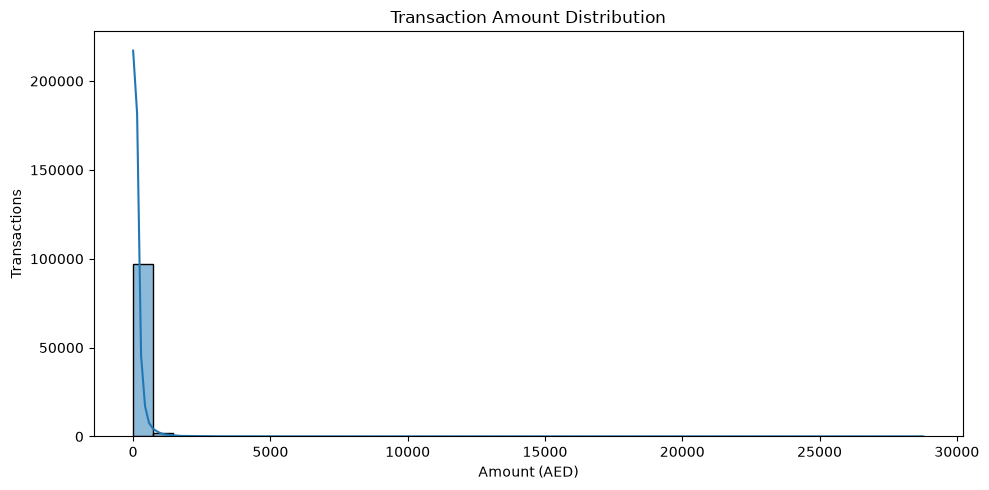

In [9]:
if AMOUNT_COL:
    plt.figure(figsize=(10, 5))
    sns.histplot(analysis_df[AMOUNT_COL].dropna(), bins=40, kde=True)
    plt.title("Transaction Amount Distribution")
    plt.xlabel("Amount (AED)")
    plt.ylabel("Transactions")
    plt.tight_layout()
    plt.show()
else: print("Amount column not found.")

### Visual 2 — Monthly transaction volume

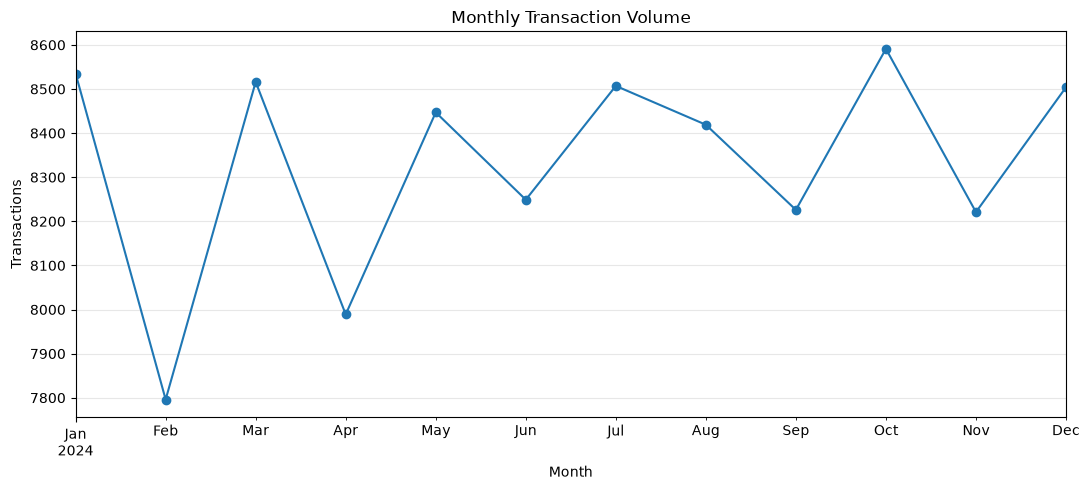

In [10]:
if DATE_COL and AMOUNT_COL and "monthly" in globals():
    monthly["transactions"].plot(figsize=(11, 5), marker="o")
    plt.title("Monthly Transaction Volume")
    plt.xlabel("Month"); plt.ylabel("Transactions")
    plt.grid(alpha=.3); plt.tight_layout(); plt.show()
else: print("Monthly data unavailable.")

### Visual 3 — Monthly GTV

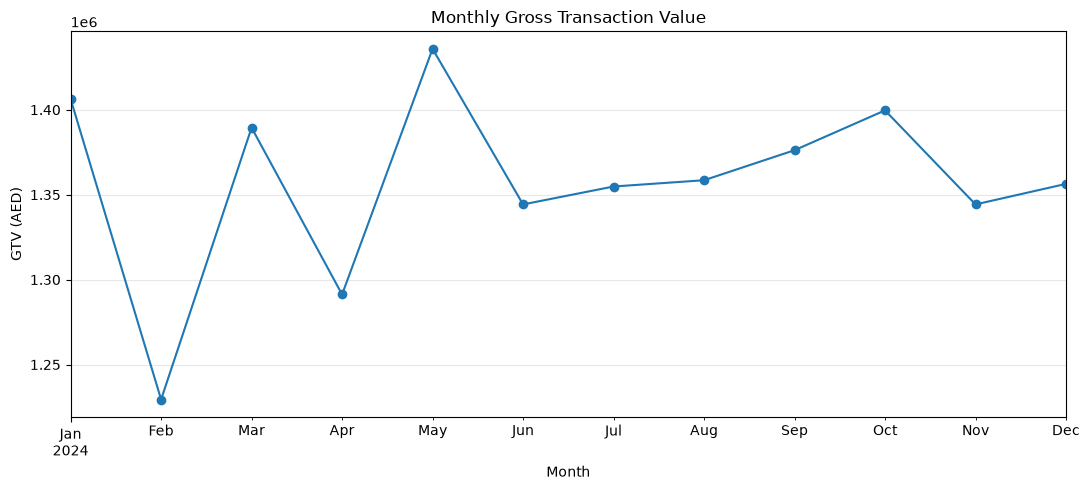

In [11]:
if DATE_COL and AMOUNT_COL and "monthly" in globals():
    monthly["GTV_AED"].plot(figsize=(11, 5), marker="o")
    plt.title("Monthly Gross Transaction Value")
    plt.xlabel("Month"); plt.ylabel("GTV (AED)")
    plt.grid(alpha=.3); plt.tight_layout(); plt.show()
else: print("Monthly data unavailable.")

### Visual 4 — Average transaction value by month

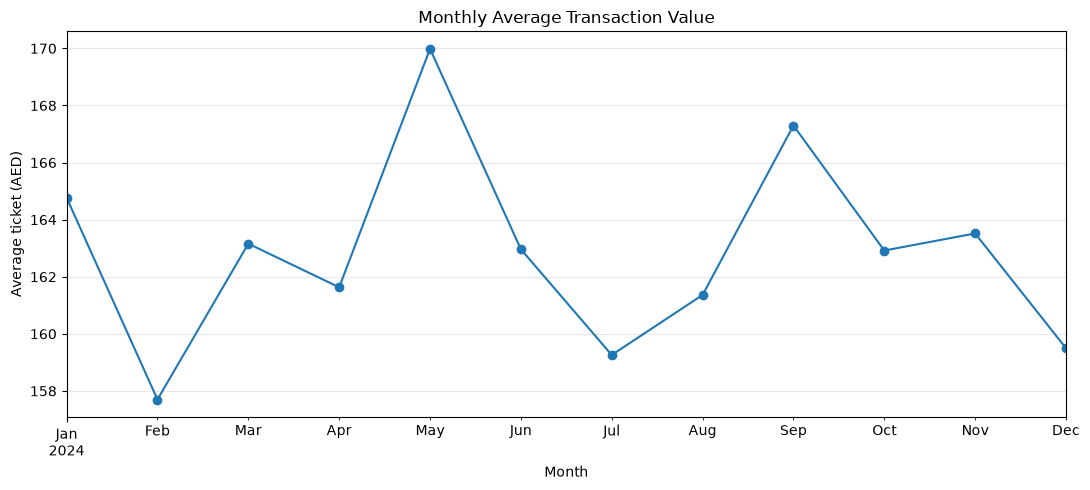

In [12]:
if DATE_COL and AMOUNT_COL and "monthly" in globals():
    monthly["average_ticket_AED"].plot(figsize=(11, 5), marker="o")
    plt.title("Monthly Average Transaction Value")
    plt.xlabel("Month"); plt.ylabel("Average ticket (AED)")
    plt.grid(alpha=.3); plt.tight_layout(); plt.show()
else: print("Monthly data unavailable.")

### Visual 5 — GTV by city

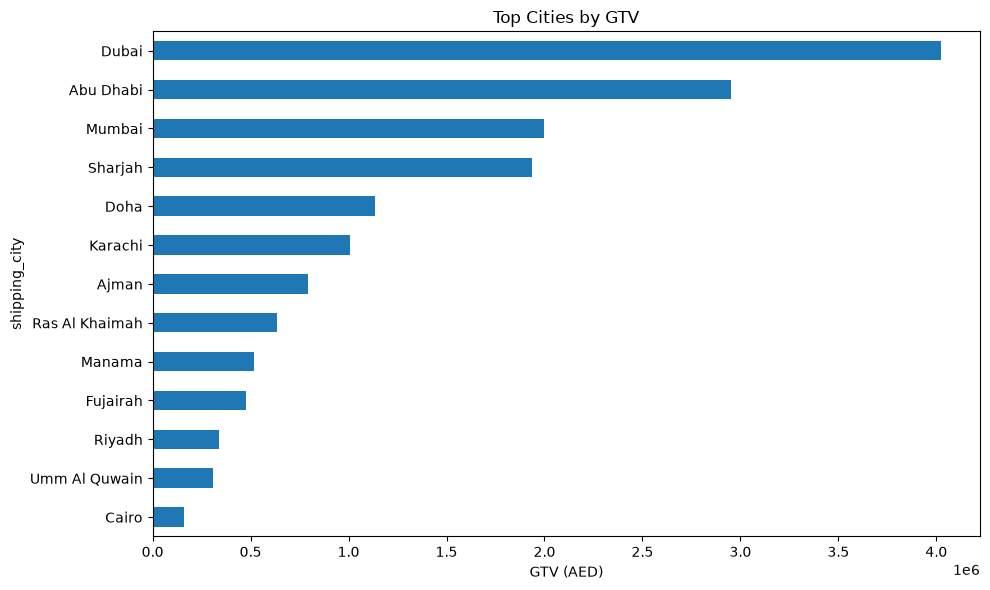

In [13]:
if "shipping_city" in segment_tables:
    s = segment_tables["shipping_city"]["GTV_AED"].head(15).sort_values()
    plt.figure(figsize=(10, 6)); s.plot(kind="barh")
    plt.title("Top Cities by GTV"); plt.xlabel("GTV (AED)")
    plt.tight_layout(); plt.show()
else: print("shipping_city not found.")

### Visual 6 — GTV by merchant category

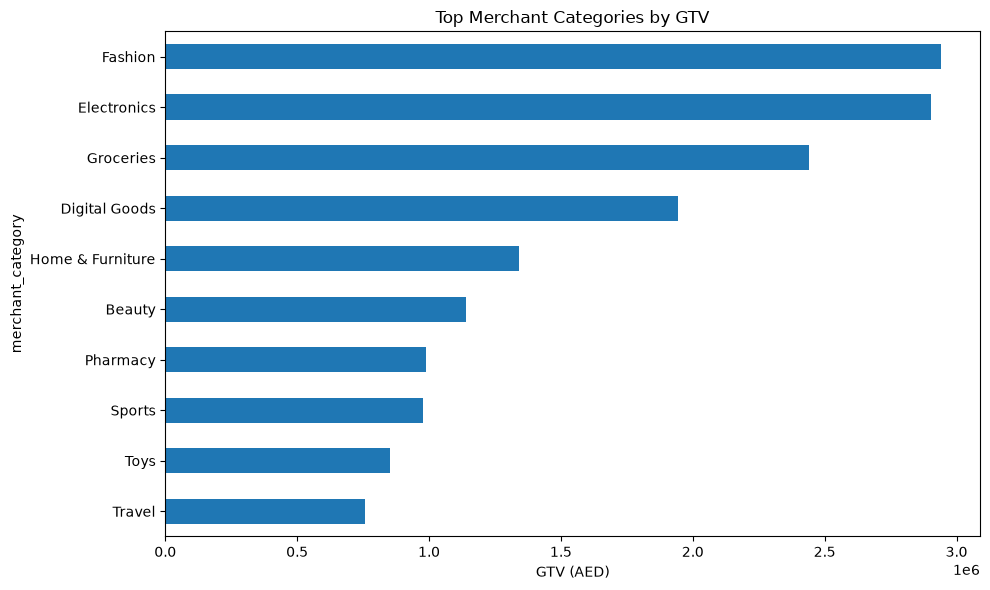

In [14]:
if "merchant_category" in segment_tables:
    s = segment_tables["merchant_category"]["GTV_AED"].head(15).sort_values()
    plt.figure(figsize=(10, 6)); s.plot(kind="barh")
    plt.title("Top Merchant Categories by GTV"); plt.xlabel("GTV (AED)")
    plt.tight_layout(); plt.show()
else: print("merchant_category not found.")

### Visual 7 — GTV by payment method

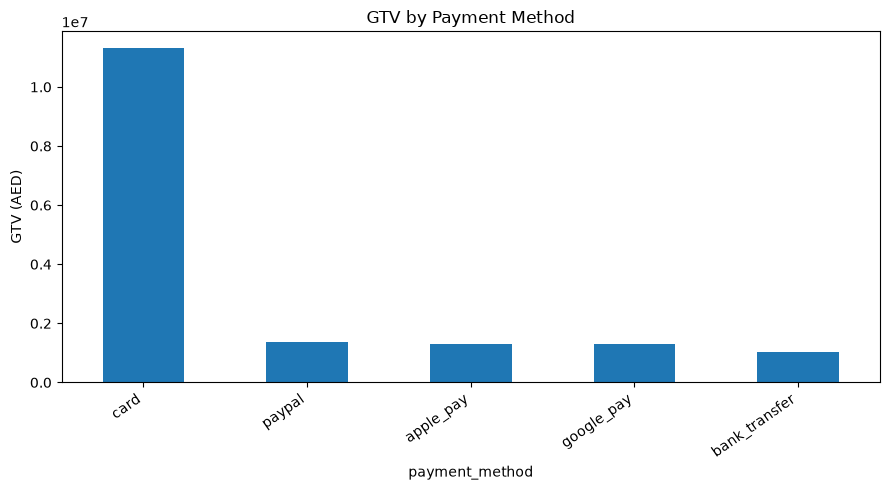

In [15]:
if "payment_method" in segment_tables:
    s = segment_tables["payment_method"]["GTV_AED"].sort_values(ascending=False)
    plt.figure(figsize=(9, 5)); s.plot(kind="bar")
    plt.title("GTV by Payment Method"); plt.ylabel("GTV (AED)")
    plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()
else: print("payment_method not found.")

### Visual 8 — Fraud-labelled transaction counts

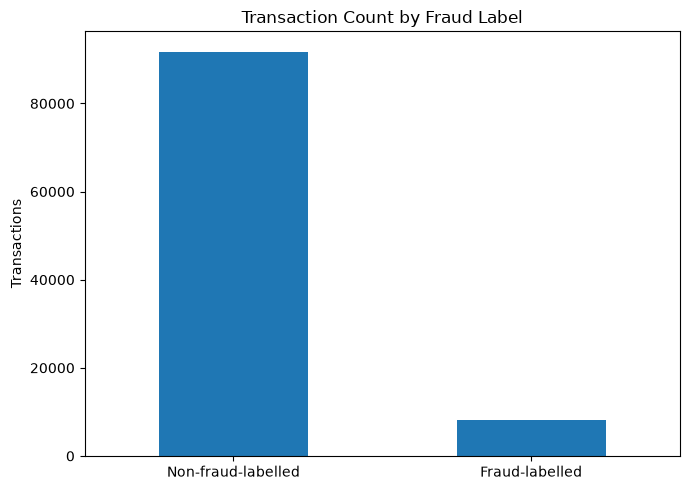

In [16]:
if FRAUD_COL:
    fm = analysis_df[FRAUD_COL].astype(str).str.lower().isin(["1", "true", "yes", "fraud"])
    counts = pd.Series({"Non-fraud-labelled": (~fm).sum(), "Fraud-labelled": fm.sum()})
    plt.figure(figsize=(7, 5)); counts.plot(kind="bar")
    plt.title("Transaction Count by Fraud Label"); plt.ylabel("Transactions")
    plt.xticks(rotation=0); plt.tight_layout(); plt.show()
else: print("Fraud label not found.")

### Visual 9 — Fraud-labelled value exposure

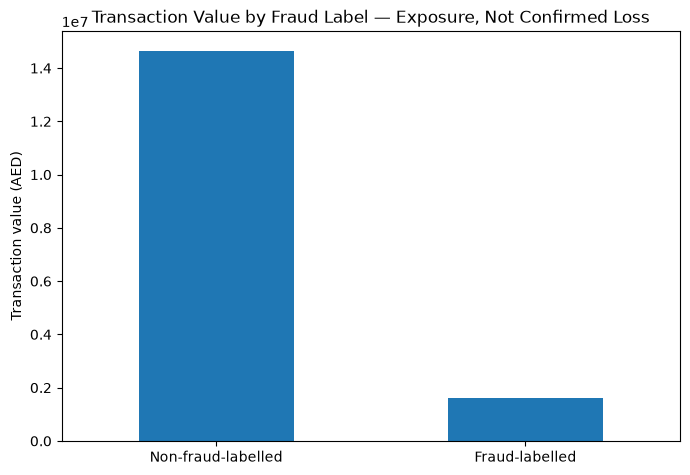

In [17]:
if FRAUD_COL and AMOUNT_COL:
    fm = analysis_df[FRAUD_COL].astype(str).str.lower().isin(["1", "true", "yes", "fraud"])
    values = pd.Series({"Non-fraud-labelled": analysis_df.loc[~fm, AMOUNT_COL].sum(),
                        "Fraud-labelled": analysis_df.loc[fm, AMOUNT_COL].sum()})
    plt.figure(figsize=(7, 5)); values.plot(kind="bar")
    plt.title("Transaction Value by Fraud Label — Exposure, Not Confirmed Loss")
    plt.ylabel("Transaction value (AED)"); plt.xticks(rotation=0)
    plt.tight_layout(); plt.show()
else: print("Fraud label or amount field not found.")

### Visual 10 — Numeric correlation heatmap

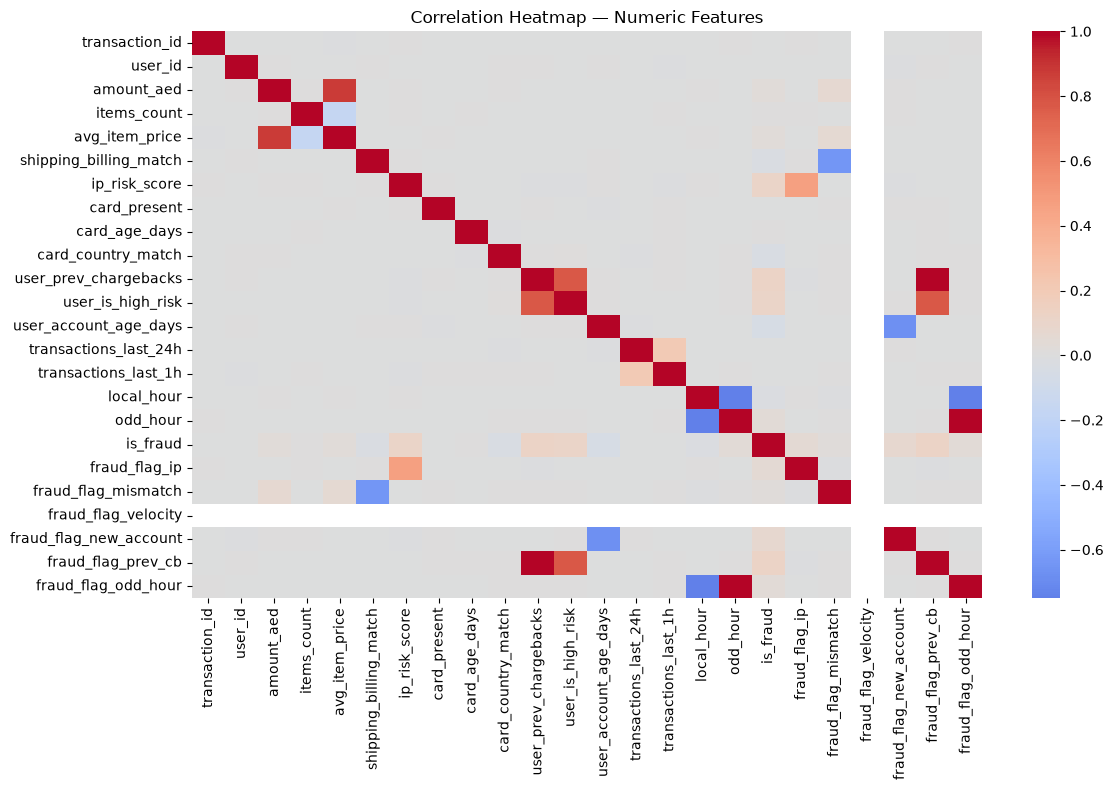

In [18]:
numeric = analysis_df.select_dtypes(include=np.number)
if numeric.shape[1] >= 2:
    plt.figure(figsize=(12, 8))
    sns.heatmap(numeric.corr(), cmap="coolwarm", center=0)
    plt.title("Correlation Heatmap — Numeric Features")
    plt.tight_layout(); plt.show()
else: print("At least two numeric columns are required.")

## 9. Profit and loss analysis — only with verified accounting fields

In [19]:
# Edit these values after confirming the data dictionary.
REVENUE_FIELD = None  # Example: platform_revenue_aed
COST_FIELDS = []      # Example: payment_processing_cost_aed, fulfillment_cost_aed

if REVENUE_FIELD and REVENUE_FIELD in analysis_df.columns and COST_FIELDS and all(x in analysis_df.columns for x in COST_FIELDS):
    pnl = analysis_df[[REVENUE_FIELD] + COST_FIELDS].apply(pd.to_numeric, errors="coerce").fillna(0)
    pnl["total_cost_AED"] = pnl[COST_FIELDS].sum(axis=1)
    pnl["profit_loss_AED"] = pnl[REVENUE_FIELD] - pnl["total_cost_AED"]
    print("Revenue AED:", pnl[REVENUE_FIELD].sum())
    print("Costs AED:", pnl["total_cost_AED"].sum())
    print("Profit/loss AED:", pnl["profit_loss_AED"].sum())
    display(pnl.describe())
else:
    print("Actual P&L cannot be calculated: verified revenue and cost columns are not configured.")
    print("GTV must not be treated as revenue or profit.")

Actual P&L cannot be calculated: verified revenue and cost columns are not configured.
GTV must not be treated as revenue or profit.


## 10. Additional analysis — outlier and high-value transactions

In [20]:
if AMOUNT_COL:
    q1 = analysis_df[AMOUNT_COL].quantile(.25)
    q3 = analysis_df[AMOUNT_COL].quantile(.75)
    upper_limit = q3 + 1.5 * (q3 - q1)
    high_value = analysis_df[analysis_df[AMOUNT_COL] > upper_limit].sort_values(AMOUNT_COL, ascending=False)
    print("IQR high-value threshold (AED):", round(upper_limit, 2))
    print("High-value transaction count:", len(high_value))
    display(high_value.head(25))

IQR high-value threshold (AED): 350.16
High-value transaction count: 8627


,transaction_id,user_id,timestamp_utc,amount_aed,currency,payment_method,device_type,browser,merchant_category,items_count,...,local_hour,odd_hour,is_fraud,fraud_flag_ip,fraud_flag_mismatch,fraud_flag_velocity,fraud_flag_new_account,fraud_flag_prev_cb,fraud_flag_odd_hour,data_source
11775,500014612,1021138,2024-02-13 05:18:50+00:00,28785.92,AED,paypal,mobile,Chrome,Electronics,2,...,9,0,0,0,0,0,0,0,0,synthetic:ecom-fraud-uae-v1
19327,500070695,1004534,2024-03-12 00:30:36+00:00,20929.35,AED,card,desktop,Chrome,Digital Goods,2,...,4,1,1,0,0,0,0,0,1,synthetic:ecom-fraud-uae-v1
46993,500007294,1018323,2024-06-21 17:10:03+00:00,16563.34,AED,paypal,mobile,Safari,Fashion,3,...,21,0,1,0,0,0,0,0,0,synthetic:ecom-fraud-uae-v1
93325,500044057,1006819,2024-12-07 15:31:54+00:00,15575.00,AED,card,desktop,Safari,Beauty,3,...,19,0,0,0,0,0,0,0,0,synthetic:ecom-fraud-uae-v1
2050,500022638,1024664,2024-01-08 11:07:05+00:00,15532.89,AED,paypal,desktop,Samsung Internet,Groceries,2,...,15,0,0,0,0,0,0,0,0,synthetic:ecom-fraud-uae-v1
3707,500000357,1018074,2024-01-14 13:01:03+00:00,13917.63,AED,card,mobile,Other,Fashion,3,...,17,0,0,0,0,0,0,0,0,synthetic:ecom-fraud-uae-v1
5882,500060979,1023987,2024-01-22 10:45:09+00:00,13678.93,AED,card,mobile,Chrome,Fashion,1,...,14,0,0,0,0,0,0,0,0,synthetic:ecom-fraud-uae-v1
89933,500057295,1029441,2024-11-25 06:21:09+00:00,13562.04,AED,card,desktop,Chrome,Digital Goods,2,...,10,0,0,0,0,0,0,0,0,synthetic:ecom-fraud-uae-v1
38496,500072584,1002928,2024-05-21 13:30:26+00:00,13514.14,AED,card,mobile,Chrome,Pharmacy,1,...,17,0,0,0,0,0,0,0,0,synthetic:ecom-fraud-uae-v1
71830,500088747,1001986,2024-09-20 07:06:53+00:00,13444.81,AED,card,mobile,Safari,Groceries,4,...,11,0,0,0,0,0,1,0,0,synthetic:ecom-fraud-uae-v1


In [28]:
if AMOUNT_COL and FRAUD_COL:

    # Filter fraud-labelled transactions
    fraud_mask = analysis_df[FRAUD_COL].astype(str).str.lower().isin(
        ["1", "true", "yes", "fraud"]
    )

    fraud_items = analysis_df.loc[fraud_mask].copy()

    # Identify category column
    CATEGORY_COL = "merchant_category"

    # Select only price and category
    fraud_report = fraud_items[
        [AMOUNT_COL, CATEGORY_COL]
    ].copy()

    # Rename columns for clear output
    fraud_report = fraud_report.rename(columns={
        AMOUNT_COL: "Fraud Transaction Price (AED)",
        CATEGORY_COL: "Category"
    })

    # Sort highest price first
    fraud_report = fraud_report.sort_values(
        "Fraud Transaction Price (AED)",
        ascending=False
    )

    print("TOTAL FRAUD TRANSACTIONS:", len(fraud_report))

    display(fraud_report.head(25))

else:
    print("Amount or fraud label column not found.")

TOTAL FRAUD TRANSACTIONS: 8211


,Fraud Transaction Price (AED),Category
19327,20929.35,Digital Goods
46993,16563.34,Fashion
67009,12420.03,Home & Furniture
58113,12262.54,Home & Furniture
89483,11259.49,Groceries
12148,11074.62,Toys
65921,10846.79,Electronics
78390,10068.30,Electronics
70014,9984.37,Fashion
79897,9377.28,Fashion


In [29]:
if AMOUNT_COL and FRAUD_COL:

    # Filter fraud-labelled transactions
    fraud_mask = analysis_df[FRAUD_COL].astype(str).str.lower().isin(
        ["1", "true", "yes", "fraud"]
    )

    fraud_items = analysis_df.loc[fraud_mask].copy()

    # Calculate total fraud transaction amount
    total_fraud_amount = fraud_items[AMOUNT_COL].sum()

    print("TOTAL FRAUD TRANSACTIONS:", len(fraud_items))
    print("TOTAL FRAUD AMOUNT (AED):", f"AED {total_fraud_amount:,.2f}")
    print("AVERAGE FRAUD TRANSACTION (AED):",
          f"AED {fraud_items[AMOUNT_COL].mean():,.2f}")

else:
    print("Amount or fraud label column not found.")

TOTAL FRAUD TRANSACTIONS: 8211
TOTAL FRAUD AMOUNT (AED): AED 1,628,333.28
AVERAGE FRAUD TRANSACTION (AED): AED 198.31


### 10.1 Fraud-label rate by segment

In [21]:
if FRAUD_COL:
    temp = analysis_df.copy()
    temp["_fraud_binary"] = temp[FRAUD_COL].astype(str).str.lower().isin(["1", "true", "yes", "fraud"]).astype(int)
    for segment in ["shipping_city", "merchant_category", "payment_method", "device_type"]:
        if segment in temp.columns:
            report = temp.groupby(segment).agg(
                transactions=("_fraud_binary", "size"),
                fraud_count=("_fraud_binary", "sum"),
                fraud_rate_percent=("_fraud_binary", "mean")
            )
            report["fraud_rate_percent"] *= 100
            print("Fraud-label rate by", segment)
            display(report.sort_values("fraud_rate_percent", ascending=False))
else:
    print("No fraud label column.")

Fraud-label rate by shipping_city


,transactions,fraud_count,fraud_rate_percent
shipping_city,,,
Ras Al Khaimah,3985,347,8.707654
Umm Al Quwain,1986,169,8.509567
Mumbai,11978,1017,8.490566
Cairo,1022,86,8.414873
Dubai,25053,2101,8.386221
Doha,6958,580,8.335729
Ajman,4954,412,8.316512
Karachi,6012,492,8.183633
Sharjah,11953,956,7.997992


Fraud-label rate by merchant_category


,transactions,fraud_count,fraud_rate_percent
merchant_category,,,
Toys,4914,429,8.730159
Pharmacy,6031,522,8.655281
Groceries,15080,1281,8.494695
Electronics,17944,1487,8.286893
Digital Goods,12054,998,8.279409
Fashion,18009,1449,8.045977
Beauty,6966,553,7.938559
Sports,6016,476,7.912234
Home & Furniture,7973,630,7.901668


Fraud-label rate by payment_method


,transactions,fraud_count,fraud_rate_percent
payment_method,,,
bank_transfer,6110,531,8.690671
google_pay,7858,660,8.399084
paypal,8027,657,8.184876
card,70006,5721,8.172157
apple_pay,7999,642,8.026003


Fraud-label rate by device_type


,transactions,fraud_count,fraud_rate_percent
device_type,,,
desktop,45063,3712,8.237357
mobile,50002,4110,8.219671
tablet,4935,389,7.882472


## 11. Forecast future business trends

In [22]:
forecast_tables = {}
if DATE_COL and AMOUNT_COL and "monthly" in globals():
    from statsmodels.tsa.holtwinters import ExponentialSmoothing
    for metric in ["transactions", "GTV_AED"]:
        if len(monthly) >= 6:
            fitted = ExponentialSmoothing(
                monthly[metric].astype(float), trend="add",
                seasonal=None, initialization_method="estimated"
            ).fit()
            forecast_tables[metric] = fitted.forecast(6).clip(lower=0)
            print("Six-month forecast:", metric)
            display(forecast_tables[metric].rename("forecast").to_frame())
        else:
            print("Need at least 6 monthly observations for", metric)
else:
    print("Forecast requires date and amount fields.")

Six-month forecast: transactions


,forecast
2025-01-01 00:00:00+00:00,8455.333128
2025-02-01 00:00:00+00:00,8474.102328
2025-03-01 00:00:00+00:00,8492.871528
2025-04-01 00:00:00+00:00,8511.640728
2025-05-01 00:00:00+00:00,8530.409928
2025-06-01 00:00:00+00:00,8549.179129


Six-month forecast: GTV_AED


,forecast
2025-01-01 00:00:00+00:00,1.381162e+06
2025-02-01 00:00:00+00:00,1.385247e+06
2025-03-01 00:00:00+00:00,1.389331e+06
2025-04-01 00:00:00+00:00,1.393416e+06
2025-05-01 00:00:00+00:00,1.397501e+06
2025-06-01 00:00:00+00:00,1.401585e+06


### Visual 11 — Monthly transaction forecast

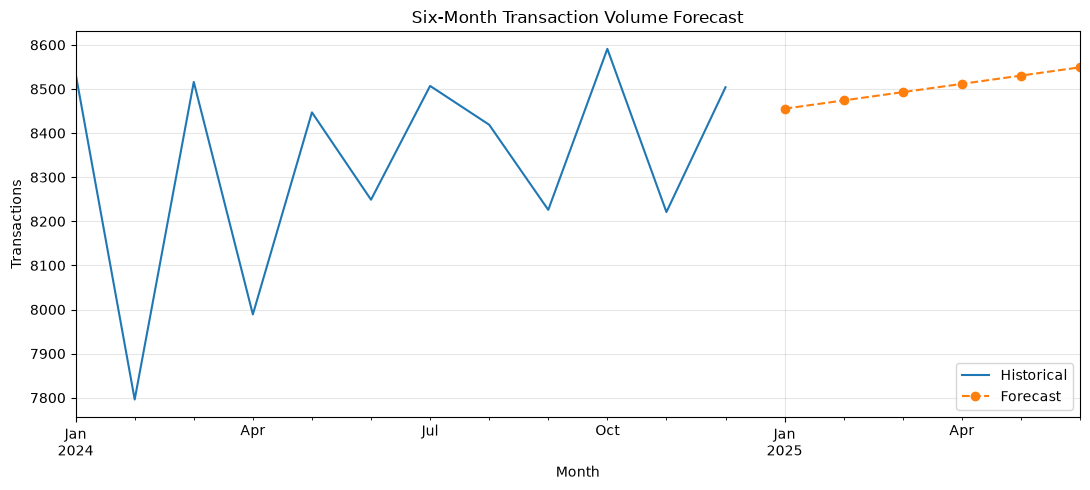

In [23]:
if "transactions" in forecast_tables:
    ax = monthly["transactions"].plot(figsize=(11, 5), label="Historical")
    forecast_tables["transactions"].plot(ax=ax, label="Forecast", marker="o", linestyle="--")
    plt.title("Six-Month Transaction Volume Forecast")
    plt.xlabel("Month"); plt.ylabel("Transactions")
    plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### Visual 12 — Monthly GTV forecast

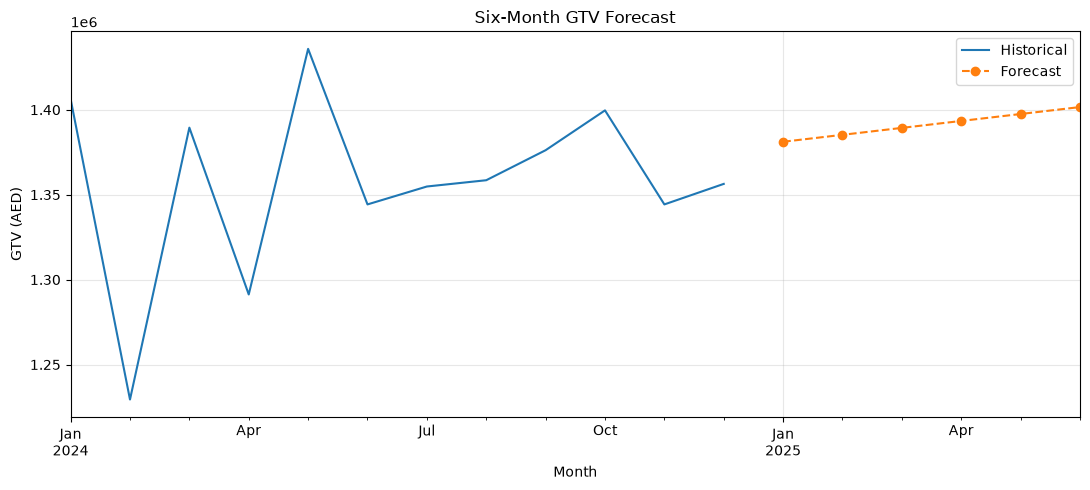

In [24]:
if "GTV_AED" in forecast_tables:
    ax = monthly["GTV_AED"].plot(figsize=(11, 5), label="Historical")
    forecast_tables["GTV_AED"].plot(ax=ax, label="Forecast", marker="o", linestyle="--")
    plt.title("Six-Month GTV Forecast")
    plt.xlabel("Month"); plt.ylabel("GTV (AED)")
    plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 12. Export analysis tables

In [25]:
from pathlib import Path
OUTPUT_DIR = Path("analytics_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
kpi_table.to_csv(OUTPUT_DIR / "business_kpis.csv", index=False)
quality_report.to_csv(OUTPUT_DIR / "data_quality_report.csv")
for segment, table in segment_tables.items():
    table.to_csv(OUTPUT_DIR / f"segment_{segment}.csv")
if "monthly" in globals():
    monthly.to_csv(OUTPUT_DIR / "monthly_business_summary.csv")
for metric, values in forecast_tables.items():
    values.rename("forecast").to_csv(OUTPUT_DIR / f"{metric}_forecast.csv")
print("Files exported to:", OUTPUT_DIR.resolve())

Files exported to: C:\Users\IQRA TRADERS\Desktop\desktop\5 project AI UAE road MAP\1.1 Sales ecommerse analysis\analytics_outputs


## 13. Create Streamlit dashboard script

In [26]:
# Creates a separate app file. Run it from PowerShell after this cell.
streamlit_app = """from pathlib import Path
import pandas as pd
import streamlit as st
import plotly.express as px

st.set_page_config(page_title='UAE E-Commerce BI', layout='wide')
st.title('UAE E-Commerce Business Intelligence')
st.caption('GTV is not profit. Fraud-labelled value is exposure, not confirmed loss.')
base = Path(__file__).parent
p = next((base / ('uae_ecom_fraud_100k' + ext) for ext in ['.csv','.parquet','.xlsx']
          if (base / ('uae_ecom_fraud_100k' + ext)).exists()), None)
if p is None:
    st.error('Put uae_ecom_fraud_100k.csv beside this app.')
    st.stop()
d = pd.read_csv(p) if p.suffix == '.csv' else (pd.read_parquet(p) if p.suffix == '.parquet' else pd.read_excel(p))
amount = next((c for c in ['amount_aed','transaction_amount','amount','sales','gtv'] if c in d), None)
date = next((c for c in ['timestamp_utc','timestamp','transaction_date','date','created_at'] if c in d), None)
fraud = next((c for c in ['is_fraud','fraud','fraud_label'] if c in d), None)
if amount:
    d[amount] = pd.to_numeric(d[amount], errors='coerce')
    a,b,c = st.columns(3)
    a.metric('Transactions', f'{len(d):,}')
    b.metric('GTV AED', f'{d[amount].sum():,.2f}')
    c.metric('Average ticket AED', f'{d[amount].mean():,.2f}')
    if fraud:
        fm = d[fraud].astype(str).str.lower().isin(['1','true','yes','fraud'])
        a,b = st.columns(2)
        a.metric('Fraud-labelled rate', f'{fm.mean()*100:.2f}%')
        b.metric('Fraud-labelled GTV exposure', f'AED {d.loc[fm,amount].sum():,.2f}')
    if date:
        d[date] = pd.to_datetime(d[date], errors='coerce')
        monthly = d.dropna(subset=[date]).set_index(date).resample('MS')[amount].sum().reset_index()
        st.plotly_chart(px.line(monthly, x=date, y=amount, title='Monthly GTV'), use_container_width=True)
    for dim in ['shipping_city','merchant_category','payment_method','device_type']:
        if dim in d:
            g = d.groupby(dim)[amount].sum().nlargest(15).reset_index()
            st.plotly_chart(px.bar(g, x=amount, y=dim, orientation='h', title=f'GTV by {dim}'), use_container_width=True)
st.subheader('Transaction explorer')
st.dataframe(d.head(1000), use_container_width=True)
"""
Path("business_analytics_dashboard.py").write_text(streamlit_app, encoding="utf-8")
print("Created business_analytics_dashboard.py")

Created business_analytics_dashboard.py


### Launch Streamlit
Run in PowerShell from the notebook folder:

```powershell
python -m pip install streamlit plotly
python -m streamlit run business_analytics_dashboard.py
```

## 14. Final analyst summary

In [27]:
print("UAE E-COMMERCE BUSINESS ANALYTICS SUMMARY")
print("Rows analysed:", f"{len(analysis_df):,}")
if AMOUNT_COL:
    print("GTV AED:", round(analysis_df[AMOUNT_COL].sum(), 2))
    print("Average transaction AED:", round(analysis_df[AMOUNT_COL].mean(), 2))
if FRAUD_COL:
    fm = analysis_df[FRAUD_COL].astype(str).str.lower().isin(["1", "true", "yes", "fraud"])
    print("Fraud-labelled rate %:", round(fm.mean() * 100, 2))
print("P&L: only calculate after mapping verified revenue and cost fields.")
print("Forecast: baseline estimate, not a guaranteed outcome.")

UAE E-COMMERCE BUSINESS ANALYTICS SUMMARY
Rows analysed: 100,000
GTV AED: 16286392.2
Average transaction AED: 162.86
Fraud-labelled rate %: 8.21
P&L: only calculate after mapping verified revenue and cost fields.
Forecast: baseline estimate, not a guaranteed outcome.
